In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Style des graphiques
sns.set_theme(style="whitegrid")

# 1. Chargement des données nettoyées
df = pd.read_csv("dataset_cleaned.csv")
df['date_achat'] = pd.to_datetime(df['date_achat'])
date_max = df['date_achat'].max()

print("=== 1. CONSTRUCTION DES MÉTRIQUES COMPORTEMENTALES PAR CLIENT ===")

# A. Résumé au niveau Ticket
tickets_summary = df.groupby(['client_id', 'ticket_id']).agg(
    nb_articles=('quantite', 'sum'),
    montant_ticket=('prix_total', 'sum'),
    date_ticket=('date_achat', 'max')
).reset_index()

# B. Métriques RFM et Paniers
client_rfm = tickets_summary.groupby('client_id').agg(
    recence=('date_ticket', lambda x: (date_max - x.max()).days),
    frequence=('ticket_id', 'count'),
    montant_total=('montant_ticket', 'sum'),
    panier_moyen_valeur=('montant_ticket', 'mean'),
    panier_moyen_articles=('nb_articles', 'mean')
).reset_index()

# C. Sensibilité aux promotions
client_promos = df.groupby('client_id').agg(
    taux_promo=('promotion', 'mean'),
    taux_reduction_moyen=('taux_reduction', 'mean')
).reset_index()

# Fusion des métriques clés
df_clients = client_rfm.merge(client_promos, on='client_id')

print(f" Nombre de clients uniques identifiés : {len(df_clients):,}")
display(df_clients.head())

=== 1. CONSTRUCTION DES MÉTRIQUES COMPORTEMENTALES PAR CLIENT ===
 Nombre de clients uniques identifiés : 5,913


,client_id,recence,frequence,montant_total,panier_moyen_valeur,panier_moyen_articles,taux_promo,taux_reduction_moyen
0,C000001,49,2,15.25,7.625000,3.500000,0.000000,0.000000
1,C000002,35,5,26.71,5.342000,4.200000,0.200000,0.025000
2,C000003,154,7,65.35,9.335714,5.714286,0.208333,0.029167
3,C000004,14,10,50.80,5.080000,3.900000,0.045455,0.009091
4,C000005,82,4,14.17,3.542500,2.500000,0.142857,0.014286


=== 2. SELECTION DES FEATURES, LOG-TRANSFORM & DIAGNOSTIC DU K ===


k = 2 | Score de Silhouette = 0.3048
k = 3 | Score de Silhouette = 0.2724
k = 4 | Score de Silhouette = 0.2613
k = 5 | Score de Silhouette = 0.2115
k = 6 | Score de Silhouette = 0.2204
k = 7 | Score de Silhouette = 0.2183
k = 8 | Score de Silhouette = 0.1985


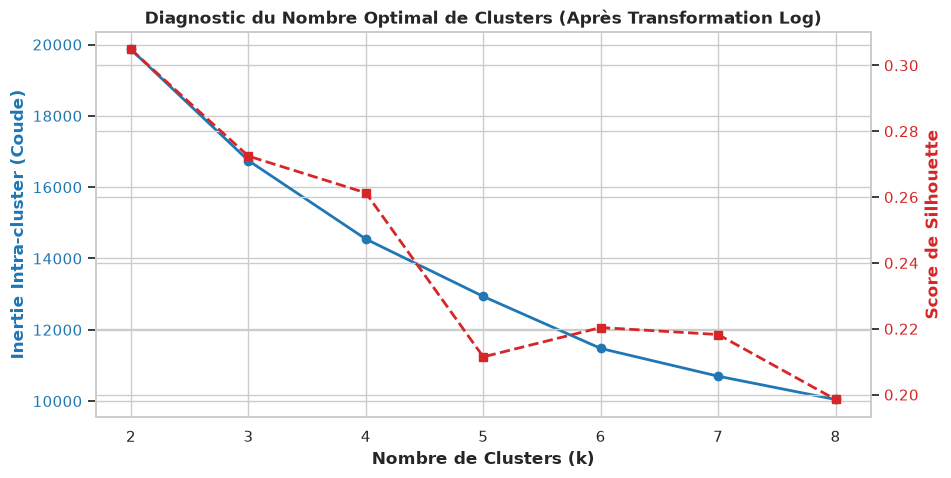

In [3]:
print("=== 2. SELECTION DES FEATURES, LOG-TRANSFORM & DIAGNOSTIC DU K ===")

# Liste des variables clés pour la segmentation
cols_rfm = ['recence', 'frequence', 'montant_total', 'panier_moyen_valeur', 'taux_promo']

# Copie pour transformation
X_clustering = df_clients[cols_rfm].copy()

# Transformation Logarithmique pour corriger l'asymétrie (Skewness)
for col in ['frequence', 'montant_total', 'panier_moyen_valeur']:
    X_clustering[col] = np.log1p(X_clustering[col])

# Standardisation (Centrée-Réduite)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clustering)

# Calcul des métriques pour k de 2 à 8
inertias = []
silhouettes = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    score = silhouette_score(X_scaled, labels)
    silhouettes.append(score)
    print(f"k = {k} | Score de Silhouette = {score:.4f}")

# Visualisation des métriques (Coude + Silhouette)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Nombre de Clusters (k)', fontweight='bold')
ax1.set_ylabel('Inertie Intra-cluster (Coude)', color=color, fontweight='bold')
ax1.plot(k_range, inertias, marker='o', color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Score de Silhouette', color=color, fontweight='bold')
ax2.plot(k_range, silhouettes, marker='s', color=color, linestyle='--', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Diagnostic du Nombre Optimal de Clusters (Après Transformation Log)", fontweight='bold')
plt.show()

In [4]:
# Choix du k optimal (k = 4 offre un excellent compromis Finesse Métier / Séparation Mathématique)
k_optimal = 4

kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=20)
df_clients['cluster'] = kmeans.fit_predict(X_scaled)

print(f"=== CLUSTERING EFFECTUÉ AVEC SUCCÈS (k = {k_optimal}) ===")
print("\n--- Répartition des clients par Cluster ---")
repartition = df_clients['cluster'].value_counts(normalize=True).sort_index() * 100

for cl, pct in repartition.items():
    nb_clients = (df_clients['cluster'] == cl).sum()
    print(f"• Cluster {cl} : {pct:.2f}% des clients ({nb_clients:,} clients)")

=== CLUSTERING EFFECTUÉ AVEC SUCCÈS (k = 4) ===

--- Répartition des clients par Cluster ---
• Cluster 0 : 45.59% des clients (2,696 clients)
• Cluster 1 : 13.31% des clients (787 clients)
• Cluster 2 : 25.03% des clients (1,480 clients)
• Cluster 3 : 16.07% des clients (950 clients)


=== CARTE D'IDENTITÉ COMPORTEMENTALE DES CLUSTERS ===


,cluster,segment_nom,Volume_Clients,Part_Pct,Recence_Moyenne_Jours,Frequence_Achat_Tickets,Montant_Total_Moyen,Panier_Moyen_Valeur,Panier_Moyen_Articles,Taux_Sensibilite_Promo
0,0,Champions / VIP,2696,45.59,33.39,7.69,88.72,11.97,6.19,15.7%
1,1,Inactifs / À risque,787,13.31,191.53,2.84,25.66,9.08,4.76,11.5%
2,2,Occasionnels / Standards,1480,25.03,47.68,4.06,27.69,7.22,4.11,8.1%
3,3,Chasseurs de promo,950,16.07,56.00,3.43,24.40,7.46,4.45,33.3%


/tmp/ipykernel_80375/2423465132.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clients, x='segment_nom', y='montant_total', ax=axes[0], palette='Blues_d')
/tmp/ipykernel_80375/2423465132.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clients, x='segment_nom', y='frequence', ax=axes[1], palette='Greens_d')
/tmp/ipykernel_80375/2423465132.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clients, x='segment_nom', y='recence', ax=axes[2], palette='Reds_d')


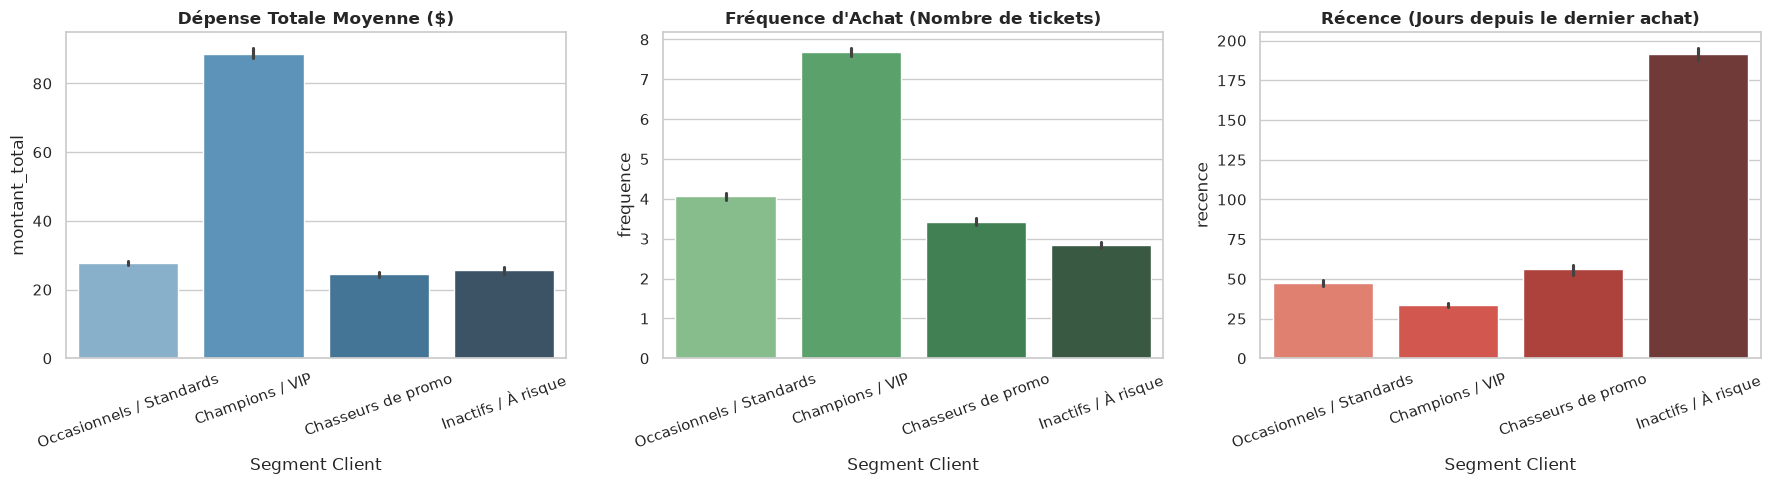

Fichier 'clients_segmentes.csv' enregistré avec succès !


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dictionnaire exact de renommage
mapping_clusters = {
    0: "Champions / VIP",
    1: "Inactifs / À risque",
    2: "Occasionnels / Standards",
    3: "Chasseurs de promo"
}

# Ajout de la colonne segment_nom dans le DataFrame
df_clients['segment_nom'] = df_clients['cluster'].map(mapping_clusters)

# 2. Calcul des moyennes réelles par cluster avec les noms métiers
cluster_profiles = df_clients.groupby(['cluster', 'segment_nom']).agg(
    Volume_Clients=('cluster', 'count'),
    Part_Pct=('cluster', lambda x: round((len(x) / len(df_clients)) * 100, 2)),
    Recence_Moyenne_Jours=('recence', 'mean'),
    Frequence_Achat_Tickets=('frequence', 'mean'),
    Montant_Total_Moyen=('montant_total', 'mean'),
    Panier_Moyen_Valeur=('panier_moyen_valeur', 'mean'),
    Panier_Moyen_Articles=('panier_moyen_articles', 'mean'),
    Taux_Sensibilite_Promo=('taux_promo', lambda x: f"{x.mean()*100:.1f}%")
).round(2).reset_index()

print("=== CARTE D'IDENTITÉ COMPORTEMENTALE DES CLUSTERS ===")
display(cluster_profiles)

# 3. Visualisation graphique des profils avec les noms métiers
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

sns.barplot(data=df_clients, x='segment_nom', y='montant_total', ax=axes[0], palette='Blues_d')
axes[0].set_title("Dépense Totale Moyenne ($)", fontweight='bold')
axes[0].set_xlabel("Segment Client")
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=df_clients, x='segment_nom', y='frequence', ax=axes[1], palette='Greens_d')
axes[1].set_title("Fréquence d'Achat (Nombre de tickets)", fontweight='bold')
axes[1].set_xlabel("Segment Client")
axes[1].tick_params(axis='x', rotation=20)

sns.barplot(data=df_clients, x='segment_nom', y='recence', ax=axes[2], palette='Reds_d')
axes[2].set_title("Récence (Jours depuis le dernier achat)", fontweight='bold')
axes[2].set_xlabel("Segment Client")
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# 4. Enregistrement du fichier segmenté avec la nouvelle colonne
df_clients.to_csv("clients_segmentes.csv", index=False)
print("Fichier 'clients_segmentes.csv' enregistré avec succès !")

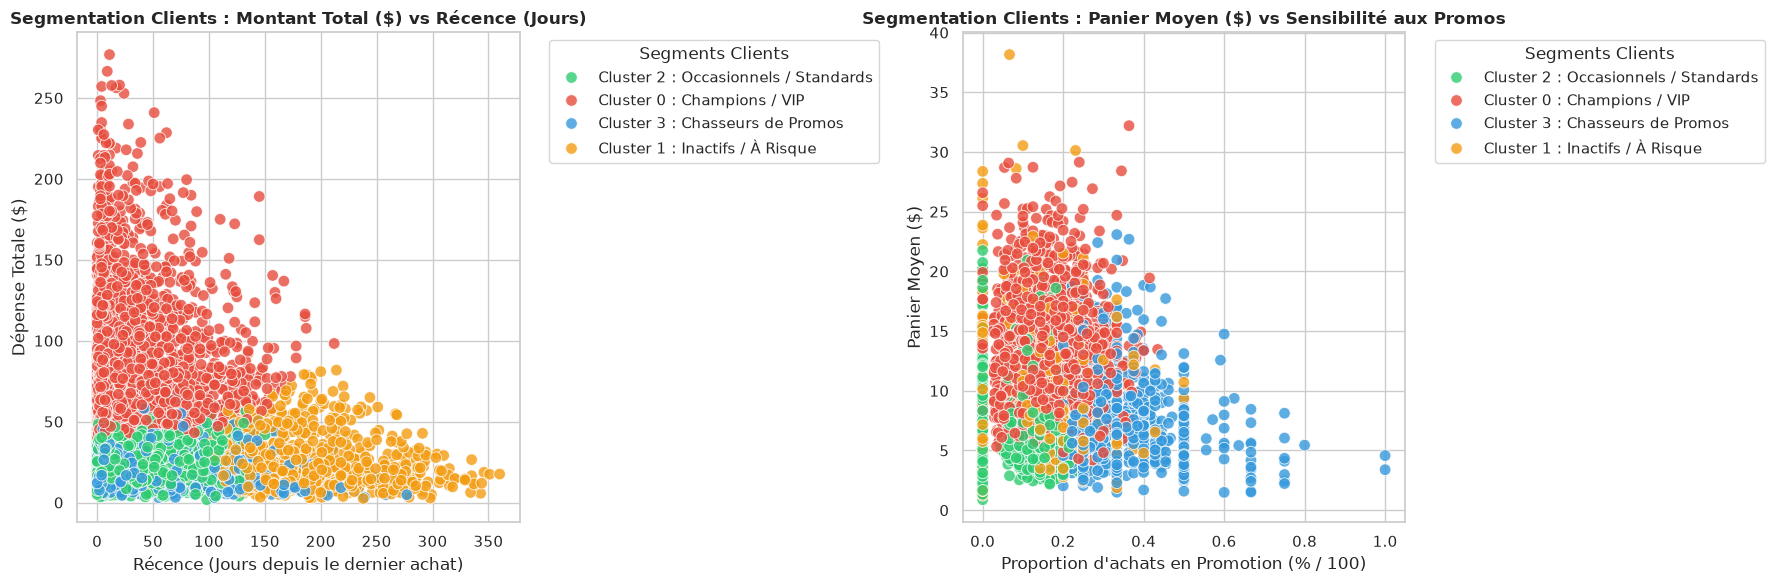

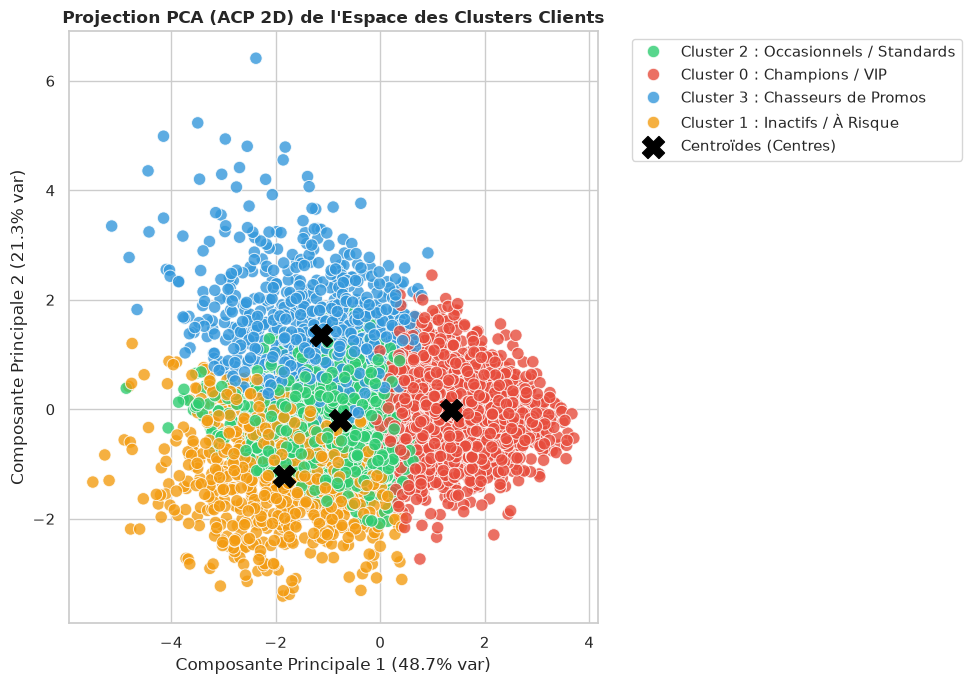

In [10]:
from sklearn.decomposition import PCA

# Définition des couleurs et noms des segments
cluster_names = {
    0: 'Cluster 0 : Champions / VIP',
    1: 'Cluster 1 : Inactifs / À Risque',
    2: 'Cluster 2 : Occasionnels / Standards',
    3: 'Cluster 3 : Chasseurs de Promos'
}

df_clients['segment_nom'] = df_clients['cluster'].map(cluster_names)
palette_colors = ['#2ecc71', '#e74c3c', '#3498db', '#f39c12'] # Vert, Rouge, Bleu, Orange

# --- FIG 1 : VUES MÉTIERS 2D ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Graphique A : Montant Total vs Récence
sns.scatterplot(
    data=df_clients, 
    x='recence', 
    y='montant_total', 
    hue='segment_nom', 
    palette=palette_colors,
    alpha=0.8,
    s=70,
    ax=axes[0]
)
axes[0].set_title("Segmentation Clients : Montant Total ($) vs Récence (Jours)", fontweight='bold')
axes[0].set_xlabel("Récence (Jours depuis le dernier achat)")
axes[0].set_ylabel("Dépense Totale ($)")
axes[0].legend(title="Segments Clients", bbox_to_anchor=(1.05, 1), loc='upper left')

# Graphique B : Panier Moyen vs Sensibilité Promo
sns.scatterplot(
    data=df_clients, 
    x='taux_promo', 
    y='panier_moyen_valeur', 
    hue='segment_nom', 
    palette=palette_colors,
    alpha=0.8,
    s=70,
    ax=axes[1]
)
axes[1].set_title("Segmentation Clients : Panier Moyen ($) vs Sensibilité aux Promos", fontweight='bold')
axes[1].set_xlabel("Proportion d'achats en Promotion (% / 100)")
axes[1].set_ylabel("Panier Moyen ($)")
axes[1].legend(title="Segments Clients", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


# --- FIG 2 : PROJECTION GLOBALE PCA (ACP 2D) ---
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled) # X_scaled issu du clustering

df_clients['pca1'] = X_pca[:, 0]
df_clients['pca2'] = X_pca[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df_clients, 
    x='pca1', 
    y='pca2', 
    hue='segment_nom', 
    palette=palette_colors,
    alpha=0.8,
    s=80
)

# Marquage des centres de clusters (Centroïdes)
centroids_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    centroids_pca[:, 0], 
    centroids_pca[:, 1], 
    marker='X', 
    s=250, 
    color='black', 
    label='Centroïdes (Centres)'
)

plt.title("Projection PCA (ACP 2D) de l'Espace des Clusters Clients", fontweight='bold')
plt.xlabel(f"Composante Principale 1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"Composante Principale 2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

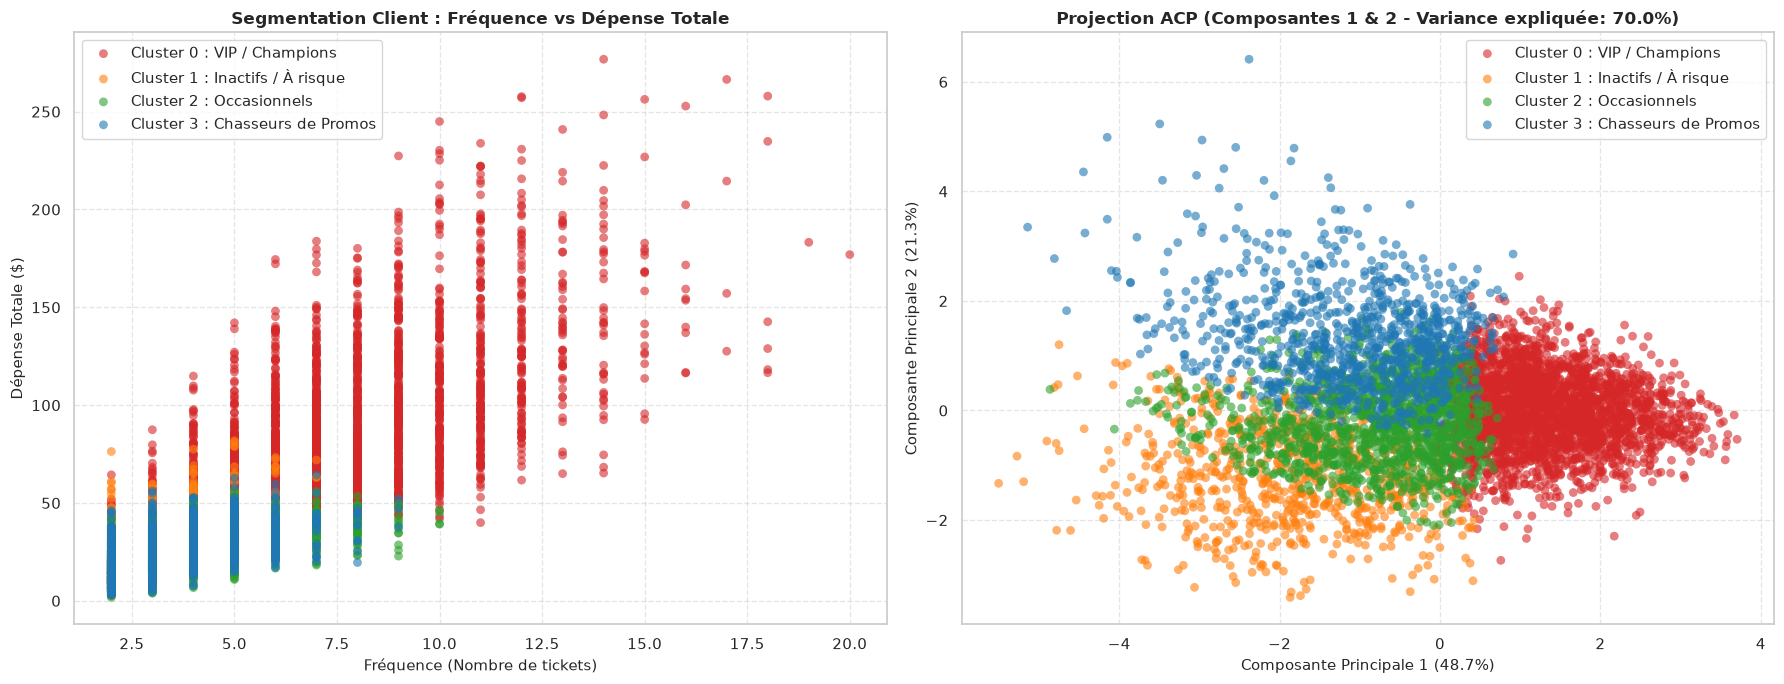

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# Define palette / colors for the 4 clusters
colors = ['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4']  # Bleu, Rouge, Vert, Orange ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e']
labels_nom = [
    'Cluster 0 : VIP / Champions',
    'Cluster 1 : Inactifs / À risque',
    'Cluster 2 : Occasionnels',
    'Cluster 3 : Chasseurs de Promos'
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# -------------------------------------------------------------------------
# GRAPH 1 : Matplotlib Pure — Fréquence vs Dépense Totale
# -------------------------------------------------------------------------
for cluster_id in range(4):
    sub_df = df_clients[df_clients['cluster'] == cluster_id]
    ax1.scatter(
        sub_df['frequence'], 
        sub_df['montant_total'], 
        c=colors[cluster_id], 
        label=labels_nom[cluster_id],
        alpha=0.6, 
        edgecolors='none', 
        s=40
    )

ax1.set_title("Segmentation Client : Fréquence vs Dépense Totale", fontsize=12, fontweight='bold')
ax1.set_xlabel("Fréquence (Nombre de tickets)", fontsize=11)
ax1.set_ylabel("Dépense Totale ($)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left', frameon=True)

# -------------------------------------------------------------------------
# GRAPH 2 : Matplotlib Pure — ACP (PCA 2D Projection)
# -------------------------------------------------------------------------
# Application de la PCA sur les features centrées-réduites
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

var_expl = pca.explained_variance_ratio_ * 100

for cluster_id in range(4):
    mask = (df_clients['cluster'] == cluster_id)
    ax2.scatter(
        X_pca[mask, 0], 
        X_pca[mask, 1], 
        c=colors[cluster_id], 
        label=labels_nom[cluster_id],
        alpha=0.6, 
        edgecolors='none', 
        s=40
    )

ax2.set_title(f"Projection ACP (Composantes 1 & 2 - Variance expliquée: {sum(var_expl):.1f}%)", fontsize=12, fontweight='bold')
ax2.set_xlabel(f"Composante Principale 1 ({var_expl[0]:.1f}%)", fontsize=11)
ax2.set_ylabel(f"Composante Principale 2 ({var_expl[1]:.1f}%)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

In [14]:
import pandas as pd
import numpy as np

# 1. Chargement du fichier CSV de segmentation généré précédemment
nom_fichier = "clients_segmentes.csv" 
df_seg = pd.read_csv(nom_fichier)

print("=" * 60)
print("1. SCHÉMA DU FICHIER (STRUCTURE EXACTE)")
print("=" * 60)
print(f"Nombre total de lignes (enregistrements) : {df_seg.shape[0]}")
print(f"Nombre total de colonnes                : {df_seg.shape[1]}")
print("\nDétail des colonnes, types et valeurs non nulles :")
df_seg.info()

print("\n" + "=" * 60)
print("2. APERÇU DES PREMIÈRES LIGNES (DONNÉES BRUTES)")
print("=" * 60)
display(df_seg.head())

print("\n" + "=" * 60)
print("3. RÉPARTITION DES CLUSTERS (VOLUMÉTRIE COMPLÈTE)")
print("=" * 60)

# Utilisation directe du couple (cluster, segment_nom)
if 'cluster' in df_seg.columns and 'segment_nom' in df_seg.columns:
    rep = df_seg.groupby(['cluster', 'segment_nom']).size().reset_index(name='Nombre_Clients')
    rep['Proportion (%)'] = (rep['Nombre_Clients'] / len(df_seg) * 100).round(2)
    rep = rep.sort_values(by='cluster').reset_index(drop=True)
    display(rep)
else:
    print("Colonnes 'cluster' ou 'segment_nom' non trouvées.")

print("\n" + "=" * 60)
print("4. MÉTRIQUES ET STATISTIQUES DESCRIPTIVES PAR CLUSTER")
print("=" * 60)

# Sélection des colonnes numériques pour l'analyse (exclut client_id et cluster)
cols_numeriques = df_seg.select_dtypes(include=[np.number]).columns.tolist()
cols_a_exclure = [col for col in cols_numeriques if 'id' in col.lower() or col == 'cluster']
cols_analyse = [col for col in cols_numeriques if col not in cols_a_exclure]

if 'cluster' in df_seg.columns and 'segment_nom' in df_seg.columns:
    # Moyennes par cluster et nom métier
    profil_moyenne = df_seg.groupby(['cluster', 'segment_nom'])[cols_analyse].mean().round(2)
    print("--- Moyennes par Cluster ---")
    display(profil_moyenne)
    
    # Médianes par cluster et nom métier
    profil_mediane = df_seg.groupby(['cluster', 'segment_nom'])[cols_analyse].median().round(2)
    print("\n--- Médianes par Cluster ---")
    display(profil_mediane)
else:
    print("Statistiques globales du fichier :")
    display(df_seg.describe().round(2))

1. SCHÉMA DU FICHIER (STRUCTURE EXACTE)
Nombre total de lignes (enregistrements) : 5913
Nombre total de colonnes                : 12

Détail des colonnes, types et valeurs non nulles :
<class 'pandas.DataFrame'>
RangeIndex: 5913 entries, 0 to 5912
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   client_id              5913 non-null   str    
 1   recence                5913 non-null   int64  
 2   frequence              5913 non-null   int64  
 3   montant_total          5913 non-null   float64
 4   panier_moyen_valeur    5913 non-null   float64
 5   panier_moyen_articles  5913 non-null   float64
 6   taux_promo             5913 non-null   float64
 7   taux_reduction_moyen   5913 non-null   float64
 8   cluster                5913 non-null   int64  
 9   segment_nom            5913 non-null   str    
 10  pca1                   5913 non-null   float64
 11  pca2                   5913 non-null  

,client_id,recence,frequence,montant_total,panier_moyen_valeur,panier_moyen_articles,taux_promo,taux_reduction_moyen,cluster,segment_nom,pca1,pca2
0,C000001,49,2,15.25,7.625000,3.500000,0.000000,0.000000,2,Occasionnels / Standards,-1.579450,-0.903490
1,C000002,35,5,26.71,5.342000,4.200000,0.200000,0.025000,2,Occasionnels / Standards,-0.613813,0.917077
2,C000003,154,7,65.35,9.335714,5.714286,0.208333,0.029167,0,Champions / VIP,0.256812,-0.375203
3,C000004,14,10,50.80,5.080000,3.900000,0.045455,0.009091,0,Champions / VIP,0.718347,0.197589
4,C000005,82,4,14.17,3.542500,2.500000,0.142857,0.014286,2,Occasionnels / Standards,-1.912338,0.537391



3. RÉPARTITION DES CLUSTERS (VOLUMÉTRIE COMPLÈTE)


,cluster,segment_nom,Nombre_Clients,Proportion (%)
0,0,Champions / VIP,2696,45.59
1,1,Inactifs / À risque,787,13.31
2,2,Occasionnels / Standards,1480,25.03
3,3,Chasseurs de promo,950,16.07



4. MÉTRIQUES ET STATISTIQUES DESCRIPTIVES PAR CLUSTER
--- Moyennes par Cluster ---


,,recence,frequence,montant_total,panier_moyen_valeur,panier_moyen_articles,taux_promo,taux_reduction_moyen,pca1,pca2
cluster,segment_nom,,,,,,,,,
0,Champions / VIP,33.39,7.69,88.72,11.97,6.19,0.16,0.03,1.36,-0.01
1,Inactifs / À risque,191.53,2.84,25.66,9.08,4.76,0.12,0.02,-1.84,-1.23
2,Occasionnels / Standards,47.68,4.06,27.69,7.22,4.11,0.08,0.01,-0.77,-0.19
3,Chasseurs de promo,56.00,3.43,24.40,7.46,4.45,0.33,0.06,-1.13,1.36



--- Médianes par Cluster ---


,,recence,frequence,montant_total,panier_moyen_valeur,panier_moyen_articles,taux_promo,taux_reduction_moyen,pca1,pca2
cluster,segment_nom,,,,,,,,,
0,Champions / VIP,22.0,7.0,78.10,11.25,5.83,0.15,0.03,1.26,-0.01
1,Inactifs / À risque,183.0,2.0,21.50,8.31,4.50,0.12,0.02,-1.81,-1.25
2,Occasionnels / Standards,43.0,4.0,28.00,6.75,4.00,0.08,0.01,-0.61,-0.19
3,Chasseurs de promo,39.0,3.0,23.06,6.87,4.25,0.30,0.05,-0.99,1.25
